In [1]:
!pip install -q langchain langchain-groq

In [3]:
import os
from google.colab import userdata
os.environ["GROQ_API_KEY"] = userdata.get("GROK_API_KEY")   # LangChain reads it from here

from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.3)

In [4]:
from typing import Literal
from pydantic import BaseModel, Field

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy flowers or book bouquets; "
                    "faq = asks about flower prices, availability, timings or policies; "
                    "other = anything else"
    )

classifier = llm.with_structured_output(Intent)

def handle(message: str) -> str:
    intent = classifier.invoke(message).intent

    if intent == "order":
        return take_order(message)
    elif intent == "faq":
        return answer_faq(message)
    else:
        return "I can help with flowers, bouquets, orders and our shop policies. What would you like?"

In [7]:
from typing_extensions import TypedDict

class FlowerShopState(TypedDict):
    message: str
    intent: str
    reply: str

In [8]:
from langgraph.graph import StateGraph, START, END

def classify(state: FlowerShopState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}

def answer_faq(state: FlowerShopState) -> dict:
    return {"reply": "…answer from search_faq…"}

builder = StateGraph(FlowerShopState)

builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)

builder.add_edge(START, "classify")
builder.add_edge("classify", "faq")
builder.add_edge("faq", END)

graph = builder.compile()

result = graph.invoke({"message": "Do you deliver flower bouquets?"})
print(result["reply"])

…answer from search_faq…


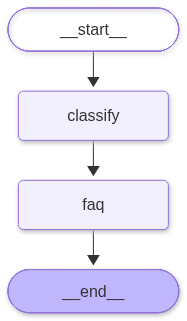

{'classify': {'intent': 'faq'}}
{'faq': {'reply': '…answer from search_faq…'}}


In [9]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

for step in graph.stream(
    {"message": "Do you deliver flower bouquets?"},
    stream_mode="updates"
):
    print(step)